<div dir="rtl">
فراخوانی کتابخانه‌های pandas و matplotlib
</div>


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

<div dir="rtl">
خواندن مجموعه داده‌ی dataset_1
</div>


In [2]:
df = pd.read_csv('dataset_1.csv', header=None)

df.head()


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<div dir="rtl">
محاسبه تعداد تراکنش‌ها
</div>

In [3]:
num_transactions = len(df)


<div dir="rtl">
محاسبه اطلاعات آماری تعداد آیتم در تراکنش‌ها
</div>

In [4]:
num_items_per_transaction = df.apply(lambda x: len(x.dropna()), axis=1)
avg_items_per_transaction = num_items_per_transaction.mean()
min_items_per_transaction = num_items_per_transaction.min()
max_items_per_transaction = num_items_per_transaction.max()
all_items = [item for sublist in df.values.tolist() for item in sublist]
num_unique_items = len(set(all_items))

<div dir="rtl">
نتایج تجزیه و تحلیل
</div>

In [5]:
print("Number of Transactions:", num_transactions)
print("Average Items per Transaction:", avg_items_per_transaction)
print("Minimum Items per Transaction:", min_items_per_transaction)
print("Maximum Items per Transaction:", max_items_per_transaction)
print("Number of unique items in all transactions:", num_unique_items)


Number of Transactions: 9835
Average Items per Transaction: 4.409456024402644
Minimum Items per Transaction: 1
Maximum Items per Transaction: 32
Number of unique items in all transactions: 170


<div dir="rtl">
نمودار هیستوگرام تعداد آیتم در هر تراکنش
</div>

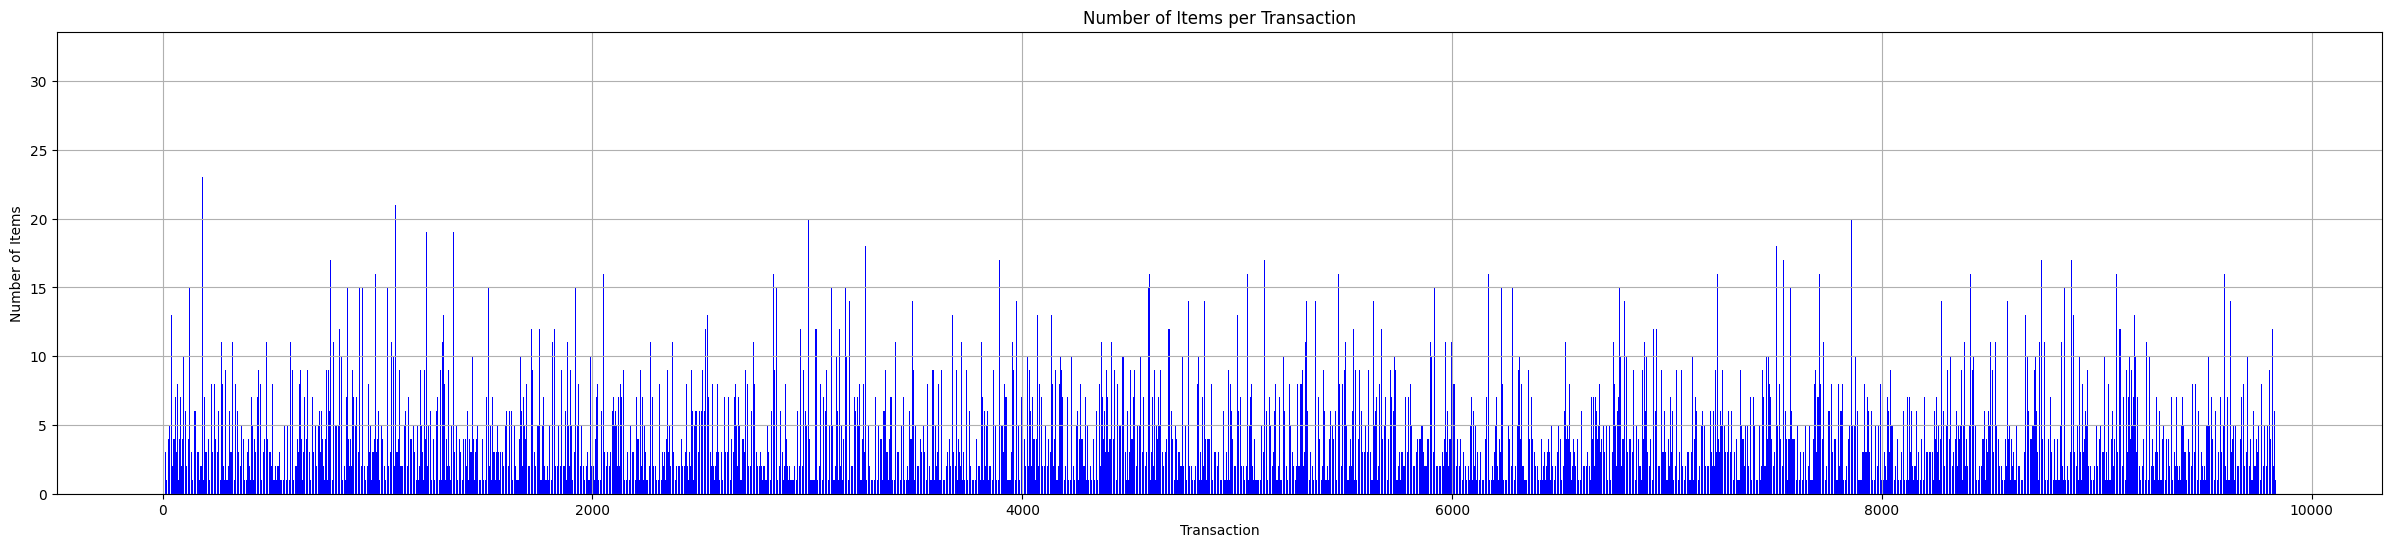

In [6]:
plt.figure(figsize=(30, 6))
plt.bar(range(len(num_items_per_transaction)), num_items_per_transaction, color='blue')
plt.xlabel('Transaction')
plt.ylabel('Number of Items')
plt.title('Number of Items per Transaction')
plt.grid(True)
plt.show()

<div dir="rtl">
نمودار هیستوگرام برای فراوانی هر آیتم منحصر به فرد در تمام تراکنش ها 
</div>

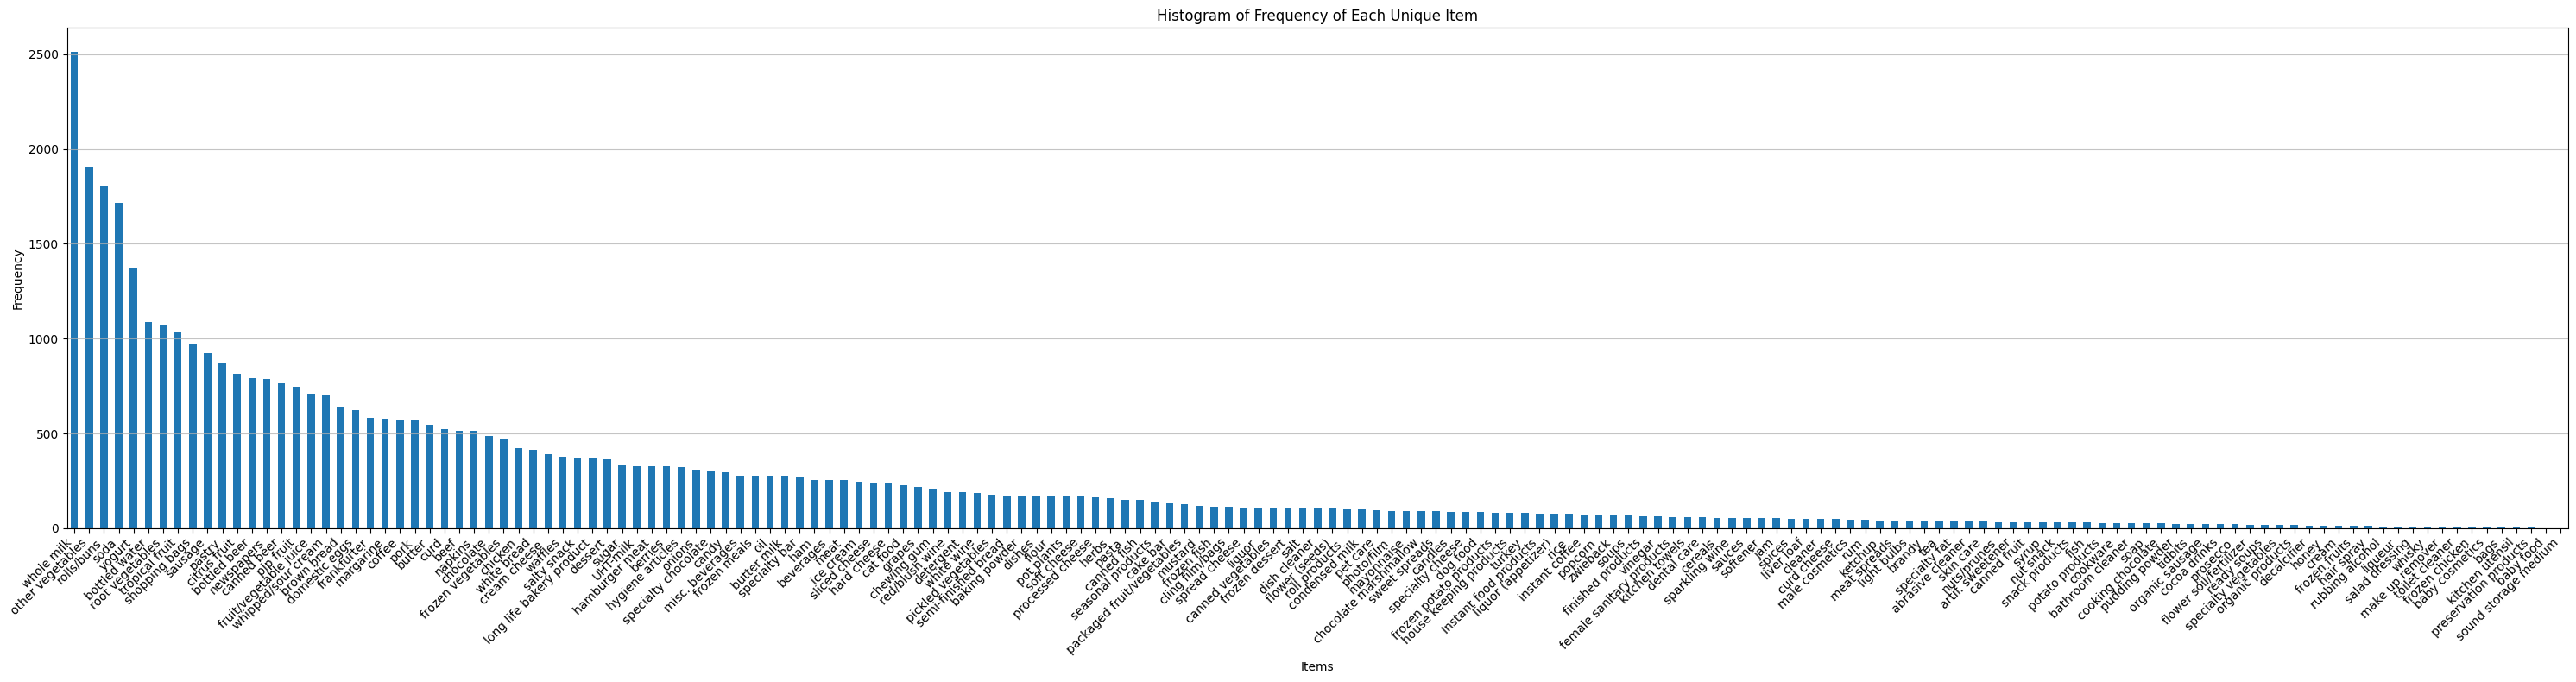

In [7]:
all_items = [item for sublist in df.values.tolist() for item in sublist]
item_counts = pd.Series(all_items).value_counts()
plt.figure(figsize=(30, 8))
item_counts.plot(kind='bar')
plt.xlabel('Items')
plt.ylabel('Frequency')
plt.title('Histogram of Frequency of Each Unique Item')
plt.grid(axis='y', alpha=0.75)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<div dir="rtl">
مجموعه داده‌ی دوم به فرمت one-hot است ولی مجموعه داده‌ی اول، خیر. بدین شکل می‌توان آن را به فرمت one-hot تبدیل کرد:
</div>


In [8]:
from mlxtend.preprocessing import TransactionEncoder
df = pd.read_csv('dataset_1.csv', header=None)

te = TransactionEncoder()
df = df.fillna('') # replace nan with ''
te_ary = te.fit(df.values).transform(df.values)

print(te.columns_)
print(te_ary)

import pandas as pd

df = pd.DataFrame(te_ary, columns=te.columns_)

df.head()


['', 'Instant food products', 'UHT-milk', 'abrasive cleaner', 'artif. sweetener', 'baby cosmetics', 'baby food', 'bags', 'baking powder', 'bathroom cleaner', 'beef', 'berries', 'beverages', 'bottled beer', 'bottled water', 'brandy', 'brown bread', 'butter', 'butter milk', 'cake bar', 'candles', 'candy', 'canned beer', 'canned fish', 'canned fruit', 'canned vegetables', 'cat food', 'cereals', 'chewing gum', 'chicken', 'chocolate', 'chocolate marshmallow', 'citrus fruit', 'cleaner', 'cling film/bags', 'cocoa drinks', 'coffee', 'condensed milk', 'cooking chocolate', 'cookware', 'cream', 'cream cheese ', 'curd', 'curd cheese', 'decalcifier', 'dental care', 'dessert', 'detergent', 'dish cleaner', 'dishes', 'dog food', 'domestic eggs', 'female sanitary products', 'finished products', 'fish', 'flour', 'flower (seeds)', 'flower soil/fertilizer', 'frankfurter', 'frozen chicken', 'frozen dessert', 'frozen fish', 'frozen fruits', 'frozen meals', 'frozen potato products', 'frozen vegetables', 'fru

,,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


# Apriori

In [9]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(df, min_support=0.005, use_colnames=True)

frequent_itemsets.head()

,support,itemsets
0,0.999898,()
1,0.008033,(Instant food products)
2,0.033452,(UHT-milk)
3,0.017692,(baking powder)
4,0.052466,(beef)


# Association rules

In [10]:
from mlxtend.frequent_patterns import association_rules

association_rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.2)

association_rules.head()


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction,zhangs_metric
0,(Instant food products),(),0.008033,0.999898,0.008033,1.000000,1.000102,8.167297e-07,inf,0.000103
1,(UHT-milk),(),0.033452,0.999898,0.033452,1.000000,1.000102,3.401317e-06,inf,0.000105
2,(baking powder),(),0.017692,0.999898,0.017692,1.000000,1.000102,1.798873e-06,inf,0.000104
3,(beef),(),0.052466,0.999898,0.052364,0.998062,0.998164,-9.634309e-05,0.052466,-0.001938
4,(berries),(),0.033249,0.999898,0.033249,1.000000,1.000102,3.380641e-06,inf,0.000105


<div dir="rtl">
مقادیر متفاوت Min support و Confidence</div>

In [11]:
from mlxtend.frequent_patterns import apriori, association_rules
import pandas as pd
min_support_values = [0.01, 0.02, 0.03, 0.04, 0.05]
confidence_values = [0.2, 0.3, 0.4, 0.5, 0.6]

results = []

for min_support in min_support_values:
    for confidence in confidence_values:
        frequent_itemsets = apriori(df, min_support=min_support, use_colnames=True)
        
        rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=confidence)
        
        results.append({'min_support': min_support, 'confidence': confidence,
                        'num_frequent_itemsets': len(frequent_itemsets),
                        'num_association_rules': len(rules)})

results_df = pd.DataFrame(results)

print(results_df)

    min_support  confidence  num_frequent_itemsets  num_association_rules
0          0.01         0.2                    663                   1024
1          0.01         0.3                    663                    698
2          0.01         0.4                    663                    511
3          0.01         0.5                    663                    369
4          0.01         0.6                    663                    329
5          0.02         0.2                    244                    337
6          0.02         0.3                    244                    230
7          0.02         0.4                    244                    166
8          0.02         0.5                    244                    124
9          0.02         0.6                    244                    121
10         0.03         0.2                    127                    139
11         0.03         0.3                    127                    105
12         0.03         0.4           

# FP-Growth


In [12]:
from mlxtend.frequent_patterns import fpgrowth

frequent_itemsets_fp = fpgrowth(df, min_support=0.005, use_colnames=True)
frequent_itemsets_fp.sort_values(by='support', ascending=False)

frequent_itemsets_fp.head()

,support,itemsets
0,0.999898,()
1,0.082766,(citrus fruit)
2,0.058566,(margarine)
3,0.017692,(semi-finished bread)
4,0.139502,(yogurt)


<div dir="rtl">
بررسی زمانی برنامه
</div>


In [13]:
import time
from mlxtend.frequent_patterns import apriori, fpgrowth

start1 = time.time()
frequent_itemsets = apriori(df, min_support=0.005, use_colnames=True)
frequent_itemsets.head()
end1 = time.time()

algorithm_time1 = end1 - start1

print(f'Time for Apriori algorithm: {algorithm_time1}')

start2 = time.time()
frequent_itemsets_fp = fpgrowth(df, min_support=0.005, use_colnames=True)
frequent_itemsets_fp.sort_values(by='support', ascending=False)
frequent_itemsets_fp.head()
end2 = time.time()

algorithm_time2 = end2 - start2

print(f'Time for FP-Growth algorithm: {algorithm_time2}')


Time for Apriori algorithm: 2.312267541885376
Time for FP-Growth algorithm: 0.1724255084991455


<div dir="rtl">
نمودا ر الگوریتم FP-Growth با 𝑚𝑖𝑛_𝑠𝑢𝑝 های مختلف</div>

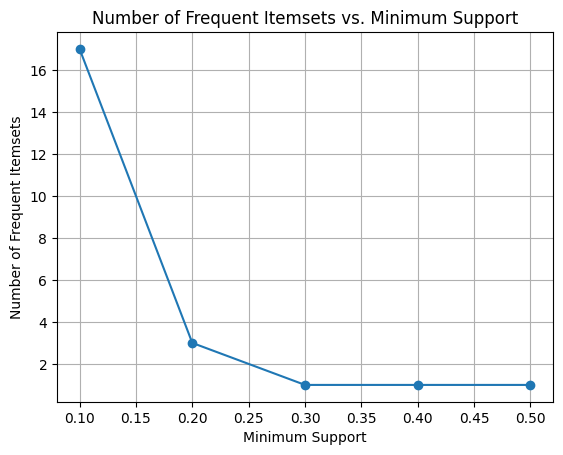

In [14]:
from mlxtend.frequent_patterns import fpgrowth
import matplotlib.pyplot as plt


min_sup_values = [0.1, 0.2, 0.3, 0.4, 0.5]

frequent_itemsets_counts = []

for min_sup in min_sup_values:
    frequent_itemsets = fpgrowth(df, min_support=min_sup, use_colnames=True)
    frequent_itemsets_counts.append(len(frequent_itemsets))

plt.plot(min_sup_values, frequent_itemsets_counts, marker='o')
plt.title('Number of Frequent Itemsets vs. Minimum Support')
plt.xlabel('Minimum Support')
plt.ylabel('Number of Frequent Itemsets')
plt.grid(True)
plt.show()
